# Problem Set 3 Problem 4

## Setup

In [2]:
import numpy as np
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import pandas as pd

## Part (a): Solve the model

Parameters and grids.

In [3]:
gamma = 5.0
beta = 0.95
T = 5
r = 0.015
mu = 0.08
sig = 0.18

maxw = np.log(50.0)
minw = np.log(1.0)
nw = 50
gw = np.linspace(minw, maxw, nw)
egw = np.exp(gw)
nc = 25

na = 21
ga = np.linspace(0.0, 1.0, na)
a = np.zeros((nw, T))
c = np.zeros((nw, T))
v = np.zeros((nw, T))


ngp = 3
gret = np.full(ngp, mu)
gret[0] = mu - sig * np.sqrt(3)
gret[2] = mu + sig * np.sqrt(3)
weight = np.array([1.0 / 6.0, 2.0 / 3.0, 1.0 / 6.0])

# Final Period
c[:, T - 1] = np.exp(gw)
v[:, T - 1] = (c[:, T - 1] ** (1 - gamma)) / (1 - gamma)

In [4]:
def compute_value_function():
    for i in range(T - 2, -1, -1):
        spline = CubicSpline(gw, v[:, i + 1], bc_type='not-a-knot')
        for z in range(nw):
            gc = np.linspace(.001, 0.999 * c[z, i + 1], nc)
            auxV = np.zeros((nc,na))
            for j in range(nc):   
                sav = np.exp(gw[z]) - gc[j]
                for k in range(na):
                    alpha = ga[k]
                    for q in range(ngp):
                        p_ret = alpha * (1+ gret[q]) + (1 - alpha) * (1+r)
                        w_t1 = np.log(p_ret * sav)
                        w_t1 = np.clip(w_t1, np.log(0.0001), maxw)
                        auxV[j,k] += weight[q] * spline(w_t1)
                    auxV[j,k] = (gc[j] ** (1 - gamma)) / (1- gamma) + beta * auxV[j,k]
                imax = np.unravel_index(np.argmax(auxV, axis=None), auxV.shape)
            v[z, i] = auxV[imax]
            c[z, i] = gc[imax[0]]
            a[z, i] = ga[imax[1]]
    return v, c , a

In [5]:
v, c, a = compute_value_function()

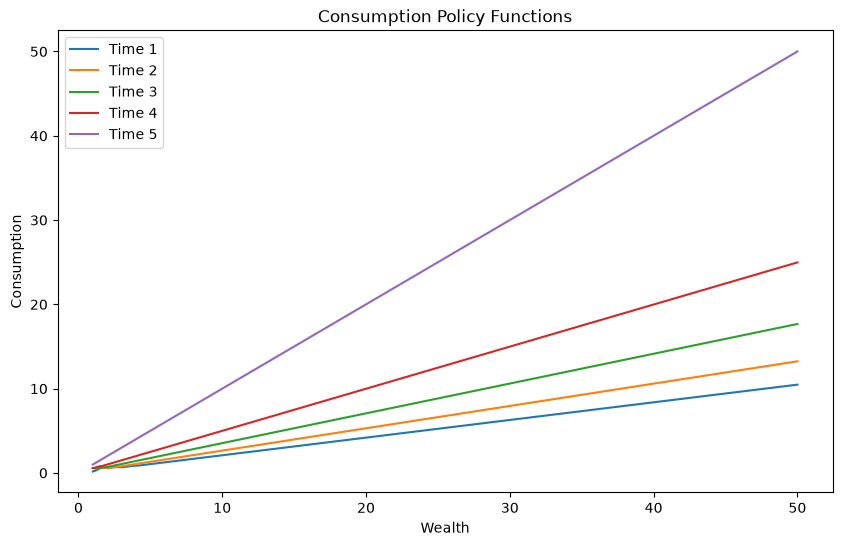

In [6]:
plt.figure(figsize=(10, 6))
for i in range(T):
    plt.plot(egw, c[:, i], label=f'Time {i+1}')
plt.title('Consumption Policy Functions')
plt.xlabel('Wealth')
plt.ylabel('Consumption')
plt.legend()
plt.show()

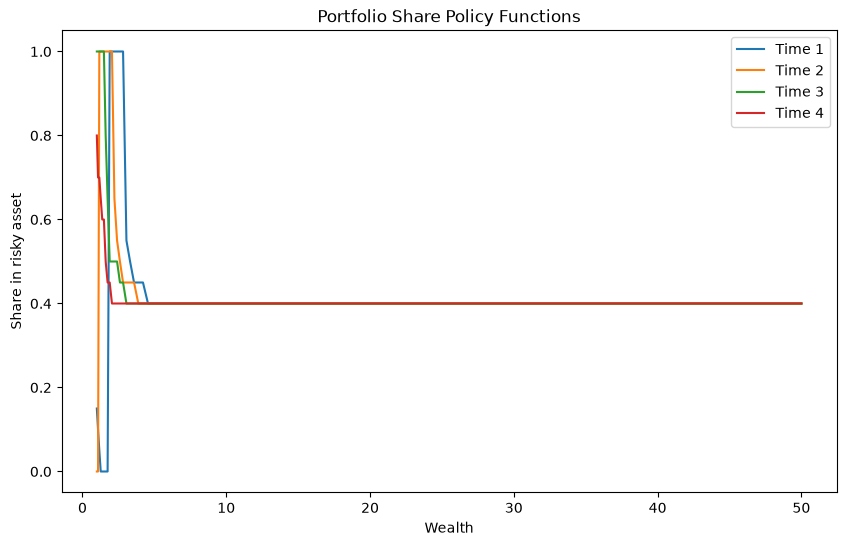

In [7]:
plt.figure(figsize=(10, 6))
for i in range(T - 1):  # period T has no saving decision
    plt.plot(egw, a[:, i], label=f'Time {i+1}')
plt.title('Portfolio Share Policy Functions')
plt.xlabel('Wealth')
plt.ylabel('Share in risky asset')
plt.ylim(-0.05, 1.05)
plt.legend()
plt.show()

## Part (b): Simulation

10,000 agents, $W_1 = 10$, seed fixed.

In [8]:
agents_c = np.zeros((10000, T))
agents_w = np.zeros((10000, T))
agents_a = np.zeros((10000, T))
agents_w[:, 0] = 10.0
for i in range(10000):
    for t in range(T):
        c_spl = np.clip(CubicSpline(gw, c[:, t], bc_type='not-a-knot')(np.log(agents_w[i, t])), 0, agents_w[i, t])
        a_spl = np.clip(CubicSpline(gw, a[:, t], bc_type='not-a-knot')(np.log(agents_w[i, t])), 0, 1)
        
        agents_c[i, t] = c_spl
        agents_a[i, t] = a_spl
        ret = np.random.normal(mu, sig)
        port_ret = a_spl * (1 + ret) + (1 - a_spl) * (1 + r)
        if t < T - 1:
            agents_w[i, t+1] = port_ret * (agents_w[i, t] - c_spl)
            
avg_c = np.mean(agents_c, axis=0)
avg_a = np.mean(agents_a, axis=0)
avg_w = np.mean(agents_w, axis=0)

Average consumption, portfolio share and wealth by period.

In [9]:
df = pd.DataFrame({
    'Consumption': avg_c,
    'Assets': avg_a,
    'Wealth': avg_w
})
df.set_index(pd.Index(range(1, T + 1)), inplace=True) 
df 

,Consumption,Assets,Wealth
1,2.095254,0.4,10.000000
2,2.179872,0.4,8.228475
3,2.224969,0.4,6.293023
4,2.115956,0.4,4.235148
5,2.204654,0.0,2.204654
